# Practical Application III: Comparing Classifiers

**Overview:** In this practical application, the goal is to compare the performance of four classifiers encountered in this section: K-Nearest Neighbors, Logistic Regression, Decision Trees, and Support Vector Machines. The dataset is related to marketing bank products over the telephone.

The notebook follows the CRISP-DM style workflow: business understanding, data understanding, data preparation, modeling, evaluation, and recommendations.

### Getting Started

The dataset comes from the UCI Machine Learning Repository and is from a Portuguese banking institution. It is a collection of the results of multiple marketing campaigns. The accompanying article (`CRISP-DM-BANK.pdf`) provides additional context on the data and features.

### Problem 1: Understanding the Data

**Question:** How many marketing campaigns does this data represent?

**Answer:** The data represents **17 marketing campaigns** run by the bank between May 2008 and November 2010. Each row is a client contact from one of those campaigns, and the target records whether the client subscribed to a term deposit.

### Problem 2: Read in the Data

Read `bank-additional-full.csv` into a pandas DataFrame using the correct separator (`;`).

In [1]:
# Standard imports and display settings used throughout the notebook
import warnings
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

In [2]:
data_path = Path("data/bank-additional-full.csv")
df = pd.read_csv(data_path, sep=";")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 41,188 | Columns: 21


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features

The data dictionary describes 20 input features and one output variable. Important data-quality points:

- There are **no literal `NaN` values** in the file.
- Several categorical variables use the label **`unknown`** as a missing-value code (`job`, `marital`, `education`, `default`, `housing`, `loan`).
- `pdays = 999` is a sentinel meaning the client was **not previously contacted**; it should not be treated as a literal 999-day gap.
- `duration` is the length of the last call. It is known only **after** the call and is highly predictive of the target, so it must be **excluded** from a realistic pre-call model.
- `month` and `day_of_week` are categorical, not numeric, even though they look like calendar values.
- Categorical variables need encoding (one-hot), and numeric variables need scaling for distance-based models such as KNN and SVM.

The code below inspects data types, missing-value codes, and summary statistics.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
feature_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "missing_values": df.isna().sum(),
    "example_value": df.iloc[0],
})
feature_summary

,dtype,n_unique,missing_values,example_value
age,int64,78,0,56
job,object,12,0,housemaid
marital,object,4,0,married
education,object,8,0,basic.4y
default,object,3,0,no
housing,object,3,0,no
loan,object,3,0,no
contact,object,2,0,telephone
month,object,10,0,may
day_of_week,object,5,0,mon


In [5]:
unknown_counts = (df.select_dtypes(include="object") == "unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0].sort_values(ascending=False)
unknown_counts

default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

In [6]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


**Interpretation:** The dataset is clean in the sense that it has no empty cells, but it is not missing-value-free: `unknown` categories and the `pdays = 999` sentinel require deliberate handling. The numeric features have very different scales (for example, `age` is roughly 17-98 while `nr.employed` is in the thousands), which is why scaling is included in the modeling pipeline.

### Data Cleaning Decisions

| Check | Finding | Decision |
|---|---|---|
| Literal missing cells | 0 `NaN` values | No row deletion needed for empty cells |
| Duplicate rows | 12 exact duplicates (0.03%) | Retained because they may represent separate campaign contacts; impact is negligible |
| `unknown` categories | Most common: `default` 8,597; `education` 1,731; `housing` 990; `loan` 990; `job` 330; `marital` 80 | Retained as an explicit category and one-hot encoded, avoiding unnecessary row deletion |
| `pdays` sentinel | 999 means "not previously contacted" | Kept as a sentinel for tree splits and standardized for linear/distance models; a binary "was contacted" flag is a possible refinement |
| `duration` | Known only after the call and strongly related to the target | Excluded from all realistic models to prevent target leakage |
| Target | `yes` / `no` text labels | Mapped to `1` / `0` for modeling |


### Problem 4: Understanding the Task

**Business objective:** Predict which clients are most likely to subscribe to a term deposit after a telephone marketing contact. The bank can use these predictions to prioritize outbound calls, target the most promising client segments, reduce wasted calling effort, and increase campaign conversion while protecting the customer experience.

This is a **binary classification** problem with a substantial class imbalance: most clients say "no". Therefore, accuracy alone is not a sufficient evaluation metric; the business cares about finding the relatively rare "yes" responses.

In [7]:
target_share = df["y"].value_counts(normalize=True).rename("share").to_frame()
target_share["count"] = df["y"].value_counts()
target_share

,share,count
y,,
no,0.887346,36548
yes,0.112654,4640


**Descriptive finding:** About **88.7%** of contacts did not subscribe and only **11.3%** did. A model that always predicts "no" would therefore appear to be about 88.7% accurate while being useless to the business. This is the key reason the analysis uses **ROC-AUC** for model selection and also reports recall and F1 for the positive ("yes") class.

### Descriptive and Inferential Statistics

Before modeling, we summarize the main patterns and run a simple inferential test to confirm that client characteristics are associated with subscription behavior.

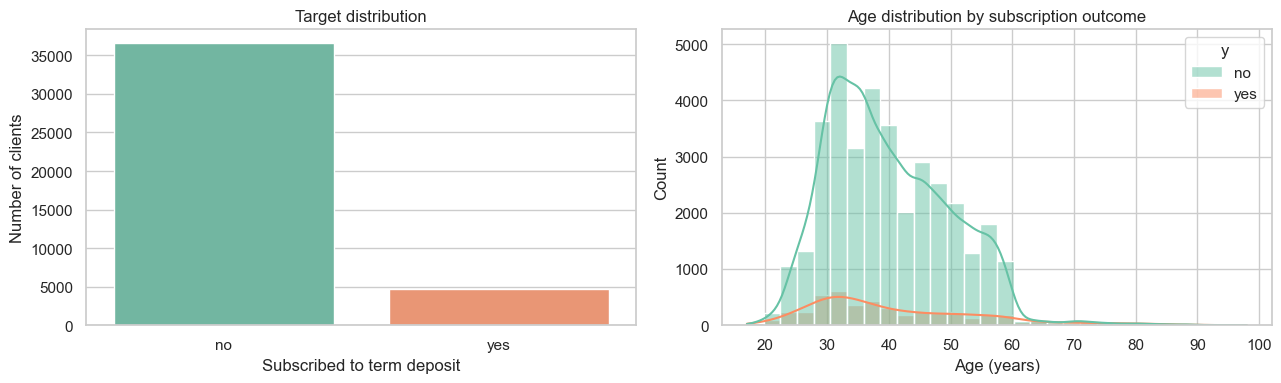

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x="y", ax=axes[0], palette="Set2")
axes[0].set_title("Target distribution")
axes[0].set_xlabel("Subscribed to term deposit")
axes[0].set_ylabel("Number of clients")

sns.histplot(data=df, x="age", hue="y", bins=30, kde=True, ax=axes[1], palette="Set2")
axes[1].set_title("Age distribution by subscription outcome")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

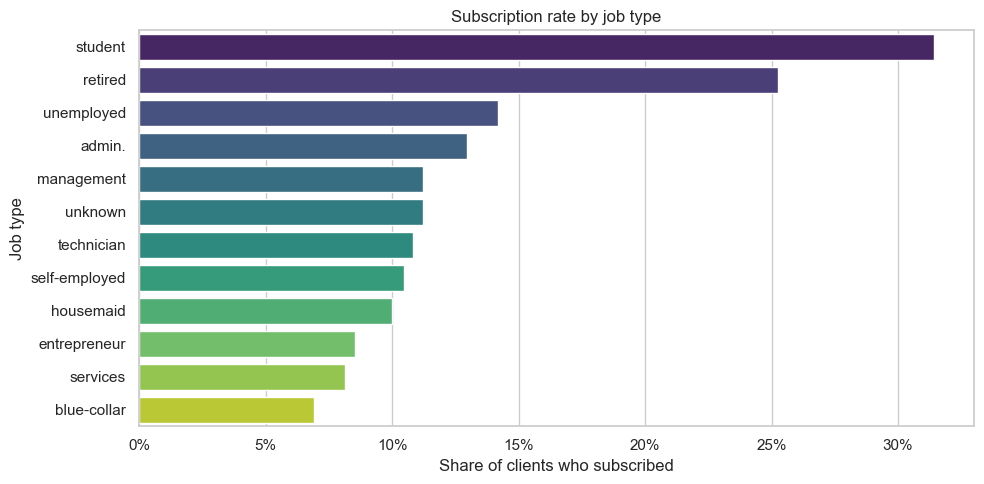

In [9]:
job_rate = (
    df.groupby("job")["y"]
    .apply(lambda s: (s == "yes").mean())
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=job_rate.values, y=job_rate.index, palette="viridis", ax=ax)
ax.set_title("Subscription rate by job type")
ax.set_xlabel("Share of clients who subscribed")
ax.set_ylabel("Job type")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.show()

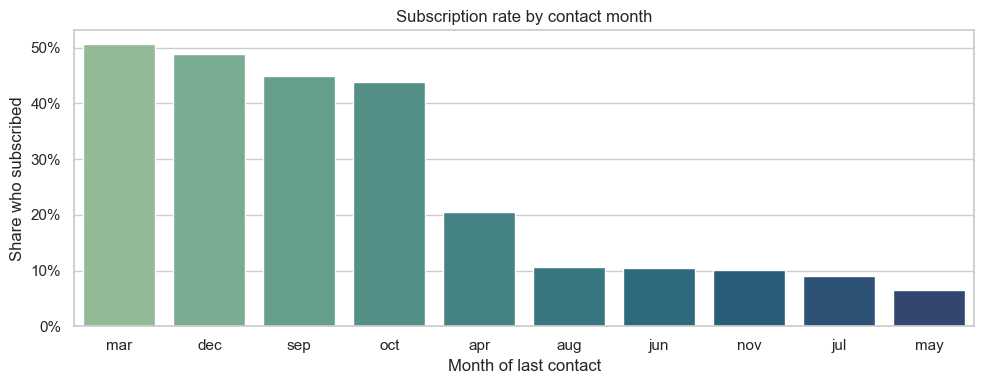

In [10]:
month_rate = (
    df.groupby("month")["y"]
    .apply(lambda s: (s == "yes").mean())
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(x=month_rate.index, y=month_rate.values, palette="crest", ax=ax)
ax.set_title("Subscription rate by contact month")
ax.set_xlabel("Month of last contact")
ax.set_ylabel("Share who subscribed")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.show()

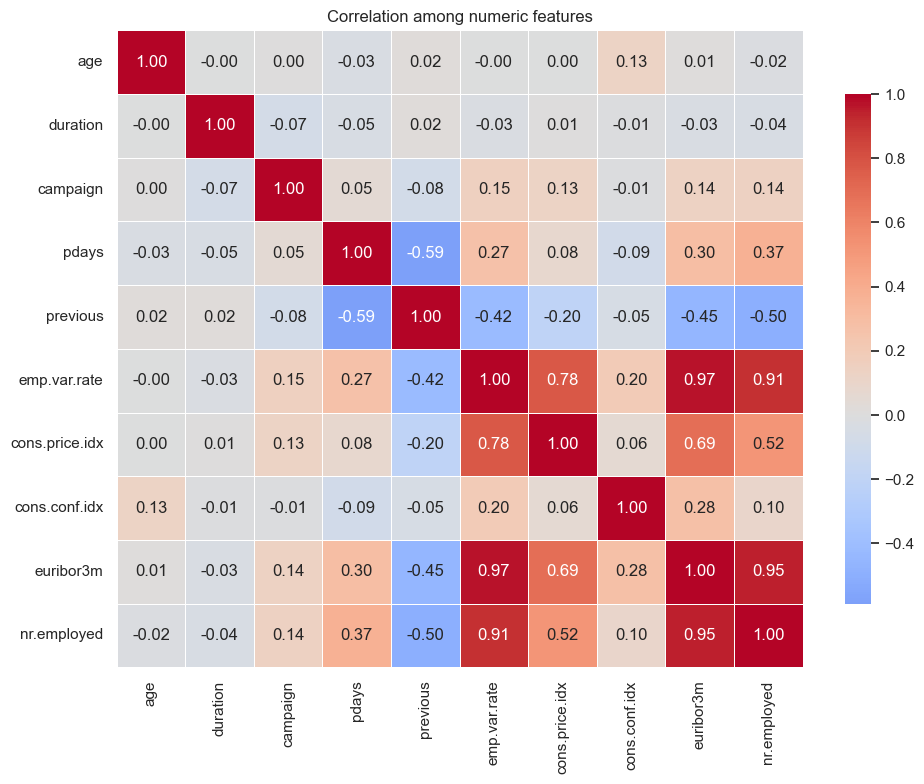

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation among numeric features")
plt.tight_layout()
plt.show()

In [12]:
job_table = pd.crosstab(df["job"], df["y"])
chi2, p_value, dof, expected = chi2_contingency(job_table)

print(f"Chi-square test: job type vs. subscription")
print(f"Chi-square statistic = {chi2:,.1f}")
print(f"Degrees of freedom   = {dof}")
print(f"p-value              = {p_value:.3e}")

Chi-square test: job type vs. subscription
Chi-square statistic = 961.2
Degrees of freedom   = 11
p-value              = 4.190e-199


**Inferential finding:** The chi-square test rejects independence between job type and subscription outcome (p-value effectively zero). Job type is statistically associated with conversion, but the effect size varies substantially: students and retired clients show the highest subscription rates, while blue-collar and services workers show lower rates. Statistical significance is not the same as business importance, so these differences are used as segmentation guidance rather than as a causal claim.

### Problem 5: Engineering Features

For the first, basic model we use **only the bank client information features**: `age`, `job`, `marital`, `education`, `default`, `housing`, and `loan`.

Preparation steps:

- One-hot encode categorical variables, with `handle_unknown="ignore"` so unseen categories do not break scoring.
- Scale numeric variables (`age`) for distance-based models.
- Encode the target as `1` for "yes" and `0` for "no".

A second feature set containing all available predictors **except `duration`** is also prepared for the improved models in Problem 11.

In [13]:
# Problem 5: use only the seven bank client information features for the basic model
bank_features = ["age", "job", "marital", "education", "default", "housing", "loan"]
X_bank = df[bank_features].copy()
y = (df["y"] == "yes").astype(int)

bank_numeric = ["age"]
bank_categorical = [c for c in bank_features if c not in bank_numeric]

bank_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), bank_numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), bank_categorical),
    ]
)

X_bank_encoded = bank_preprocessor.fit_transform(X_bank)
print(f"Encoded bank-only feature matrix: {X_bank_encoded.shape}")

Encoded bank-only feature matrix: (41188, 34)


In [14]:
model_features = [c for c in df.columns if c not in ["y", "duration"]]
X_all = df[model_features].copy()

all_numeric = X_all.select_dtypes(include=np.number).columns.tolist()
all_categorical = X_all.select_dtypes(include="object").columns.tolist()

full_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), all_numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), all_categorical),
    ]
)

X_all_encoded = full_preprocessor.fit_transform(X_all)
print(f"Encoded full feature matrix (duration excluded): {X_all_encoded.shape}")
print(f"Numeric features: {len(all_numeric)} | Categorical features: {len(all_categorical)}")

Encoded full feature matrix (duration excluded): (41188, 62)
Numeric features: 9 | Categorical features: 10


### Problem 6: Train/Test Split

Use an 80/20 stratified split so both the training and test sets preserve the original 88.7% / 11.3% class balance. The same random seed is used for the bank-only and full-feature splits so the two analyses use identical clients in each partition.

In [15]:
# Stratified 80/20 split preserves the ~11% positive-class rate in both partitions
Xb_train, Xb_test, y_train, y_test = train_test_split(
    X_bank, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

Xa_train, Xa_test, _, _ = train_test_split(
    X_all, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training rows: {len(Xb_train):,}")
print(f"Test rows:     {len(Xb_test):,}")
print(f"Training positive rate: {y_train.mean():.3%}")
print(f"Test positive rate:     {y_test.mean():.3%}")

Training rows: 32,950
Test rows:     8,238
Training positive rate: 11.266%
Test positive rate:     11.265%


### Problem 7: A Baseline Model

The majority-class baseline predicts "no" for every client. Its accuracy is the share of "no" responses in the test set. It provides a reference point, but it has **zero recall** for subscribers and a ROC-AUC of 0.5, so it is not useful in practice.

In [16]:
baseline_accuracy = y_test.value_counts(normalize=True).max()
print(f"Majority-class baseline accuracy: {baseline_accuracy:.3%}")

dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
dummy.fit(Xb_train, y_train)
dummy_pred = dummy.predict(Xb_test)

print(f"Dummy test accuracy: {accuracy_score(y_test, dummy_pred):.3f}")
print(f"Dummy positive recall: {recall_score(y_test, dummy_pred, zero_division=0):.3f}")
print(f"Dummy ROC-AUC: {roc_auc_score(y_test, dummy_pred):.3f}")

Majority-class baseline accuracy: 88.735%
Dummy test accuracy: 0.887
Dummy positive recall: 0.000
Dummy ROC-AUC: 0.500


**Baseline interpretation:** The classifier should aim to beat **88.7% accuracy**, but more importantly it should achieve a ROC-AUC meaningfully above **0.50** and find at least some of the true subscribers. Accuracy improvements of a fraction of a percentage point over the baseline can still be business-relevant if they come with useful ranking ability.

### Problem 8: A Simple Model

Build a basic Logistic Regression model on the bank-only features. Logistic Regression is a natural starting point because it is fast, stable, and its coefficients can be interpreted as changes in log-odds.

In [17]:
log_reg_bank = Pipeline(
    steps=[
        ("prep", bank_preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)

start = time.perf_counter()
log_reg_bank.fit(Xb_train, y_train)
bank_fit_time = time.perf_counter() - start
print(f"Bank-only logistic regression fit time: {bank_fit_time:.2f} seconds")

Bank-only logistic regression fit time: 0.08 seconds


### Problem 9: Score the Model

Evaluate the basic model on the held-out test set. Accuracy is reported because the assignment asks for it, but the classification report and ROC-AUC provide the more relevant view given the class imbalance.

In [18]:
bank_pred = log_reg_bank.predict(Xb_test)
bank_proba = log_reg_bank.predict_proba(Xb_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, bank_pred):.3f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, bank_proba):.3f}")
print()
print(classification_report(y_test, bank_pred, target_names=["No", "Yes"], digits=3))

Test accuracy: 0.887
Test ROC-AUC:  0.649

              precision    recall  f1-score   support

          No      0.887     1.000     0.940      7310
         Yes      0.000     0.000     0.000       928

    accuracy                          0.887      8238
   macro avg      0.444     0.500     0.470      8238
weighted avg      0.787     0.887     0.834      8238



**Answer:** The basic bank-only Logistic Regression model has an accuracy of **88.7%**, which is essentially the same as the majority-class baseline. Its ROC-AUC is **0.649**, so it does rank clients somewhat better than random, but at the default 0.5 threshold its positive-class recall is **0.000**: it predicts no subscribers. The bank-only features are therefore too weak on their own, which motivates using the broader feature set in Problem 11.

### Problem 10: Model Comparisons

Compare default Logistic Regression, K-Nearest Neighbors, Decision Tree, and Support Vector Machine models on the bank-only features. For each model we record:

- training time,
- training accuracy,
- test accuracy,
- cross-validated ROC-AUC (5-fold stratified CV on the training set),
- test ROC-AUC.

ROC-AUC is the primary comparison metric because it measures how well the model ranks clients by their probability of subscribing, independent of a specific decision threshold. Accuracy is included for completeness.

In [19]:
def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate_model(name, model, X_train, y_train, X_test, y_test, cv=5):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    test_scores = get_scores(model, X_test)

    cv_result = cross_validate(
        model,
        X_train,
        y_train,
        cv=StratifiedKFold(n_splits=cv, shuffle=True, random_state=RANDOM_STATE),
        scoring={"accuracy": "accuracy", "roc_auc": "roc_auc"},
        n_jobs=-1,
    )

    return {
        "Model": name,
        "Train Time (s)": fit_time,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "CV ROC-AUC": cv_result["test_roc_auc"].mean(),
        "Test ROC-AUC": roc_auc_score(y_test, test_scores),
        "Test Recall (Yes)": recall_score(y_test, test_pred, zero_division=0),
        "Test F1 (Yes)": f1_score(y_test, test_pred, zero_division=0),
    }

In [20]:
# Default settings for the four classifiers required by the assignment
default_models = {
    "Logistic Regression": Pipeline([
        ("prep", bank_preprocessor),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("prep", bank_preprocessor),
        ("model", KNeighborsClassifier()),
    ]),
    "Decision Tree": Pipeline([
        ("prep", bank_preprocessor),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "Support Vector Machine": Pipeline([
        ("prep", bank_preprocessor),
        ("model", SVC()),
    ]),
}

comparison_rows = [
    evaluate_model(name, model, Xb_train, y_train, Xb_test, y_test)
    for name, model in default_models.items()
]

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Model")
    .sort_values("Test ROC-AUC", ascending=False)
)

comparison.round(3)

,Train Time (s),Train Accuracy,Test Accuracy,CV ROC-AUC,Test ROC-AUC,Test Recall (Yes),Test F1 (Yes)
Model,,,,,,,
Logistic Regression,0.084,0.887,0.887,0.649,0.649,0.000,0.000
K-Nearest Neighbors,0.043,0.892,0.881,0.586,0.591,0.073,0.121
Support Vector Machine,41.249,0.888,0.886,0.569,0.580,0.005,0.011
Decision Tree,0.129,0.917,0.865,0.572,0.575,0.088,0.128


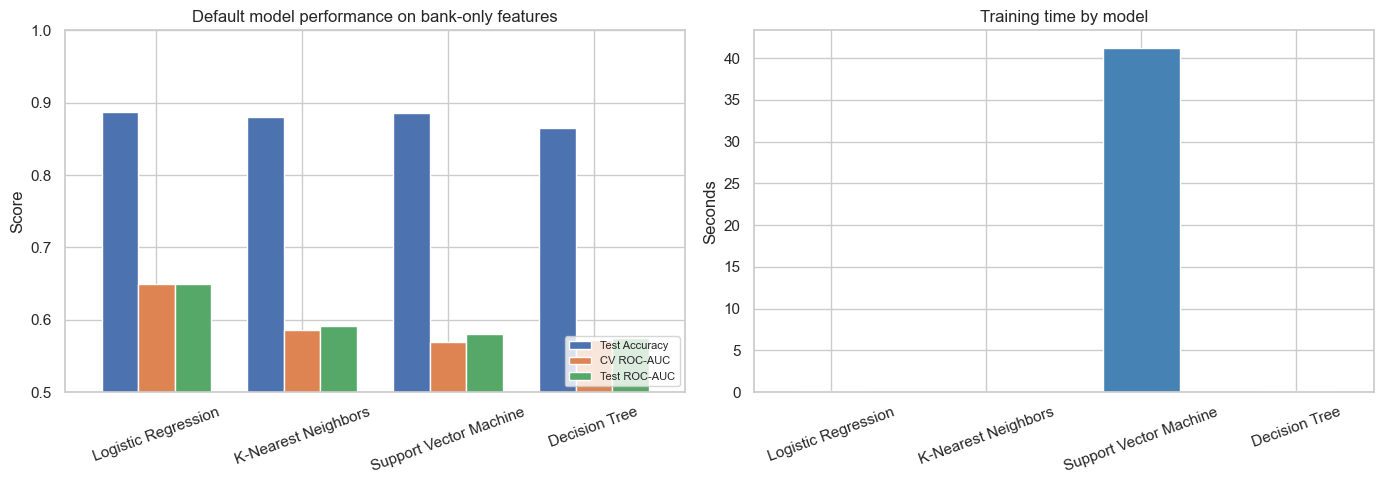

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

comparison[["Test Accuracy", "CV ROC-AUC", "Test ROC-AUC"]].plot(
    kind="bar", ax=axes[0], width=0.75
)
axes[0].set_title("Default model performance on bank-only features")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.5, 1.0)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(loc="lower right", fontsize=8)

comparison["Train Time (s)"].plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Training time by model")
axes[1].set_xlabel("")
axes[1].set_ylabel("Seconds")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**Comparison interpretation:** On the bank-only features, all four models are close to the majority-class baseline in accuracy because the signal in those seven features is limited.

| Model | Test Accuracy | Test ROC-AUC | Test Recall (Yes) |
|---|---:|---:|---:|
| Logistic Regression | 0.887 | 0.649 | 0.000 |
| K-Nearest Neighbors | 0.881 | 0.591 | 0.073 |
| Support Vector Machine | 0.886 | 0.580 | 0.005 |
| Decision Tree | 0.865 | 0.575 | 0.088 |

The Decision Tree overfits: its training accuracy is **0.917** but its test accuracy is **0.865**. KNN and SVM are sensitive to scaling and to the large number of non-subscribers, and they do not outperform the simpler logistic benchmark. Logistic Regression gives the best bank-only ROC-AUC (**0.649**) and remains the most interpretable benchmark. The key conclusion is that better features, not just a more complex algorithm, are needed to improve conversion prediction.

### Problem 11: Improving the Model

Three improvements are explored:

1. **Add the broader feature set** (all predictors except `duration`, which would leak post-call information).
2. **Tune hyperparameters with grid search** and stratified cross-validation.
3. **Use ROC-AUC as the selection metric** because the target is imbalanced and the business needs a reliable ranking of likely subscribers.

The SVM grid search is run on a stratified 12,000-row subset of the training data because a full grid search over the full training set is computationally expensive; the best SVM configuration is then refit on the full training set.

In [22]:
# Three-fold stratified CV keeps grid search runtime manageable
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

log_search = GridSearchCV(
    Pipeline([
        ("prep", full_preprocessor),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    ]),
    param_grid={
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
)
log_search.fit(Xa_train, y_train)
print(f"Best logistic params: {log_search.best_params_}")
print(f"Best logistic CV ROC-AUC: {log_search.best_score_:.4f}")

Best logistic params: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best logistic CV ROC-AUC: 0.7907


In [23]:
knn_search = GridSearchCV(
    Pipeline([
        ("prep", full_preprocessor),
        ("model", KNeighborsClassifier()),
    ]),
    param_grid={
        "model__n_neighbors": [5, 15, 31],
        "model__weights": ["uniform", "distance"],
    },
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
)
knn_search.fit(Xa_train, y_train)
print(f"Best KNN params: {knn_search.best_params_}")
print(f"Best KNN CV ROC-AUC: {knn_search.best_score_:.4f}")

Best KNN params: {'model__n_neighbors': 31, 'model__weights': 'uniform'}
Best KNN CV ROC-AUC: 0.7691


In [24]:
tree_search = GridSearchCV(
    Pipeline([
        ("prep", full_preprocessor),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    param_grid={
        "model__max_depth": [4, 6, 8, None],
        "model__min_samples_leaf": [5, 20, 50],
    },
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
)
tree_search.fit(Xa_train, y_train)
print(f"Best tree params: {tree_search.best_params_}")
print(f"Best tree CV ROC-AUC: {tree_search.best_score_:.4f}")

Best tree params: {'model__max_depth': 8, 'model__min_samples_leaf': 20}
Best tree CV ROC-AUC: 0.7861


In [25]:
X_svm_tune, _, y_svm_tune, _ = train_test_split(
    Xa_train, y_train, train_size=12000, random_state=RANDOM_STATE, stratify=y_train
)

svm_search = GridSearchCV(
    Pipeline([
        ("prep", full_preprocessor),
        ("model", SVC()),
    ]),
    param_grid={
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", "auto"],
    },
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
)
svm_search.fit(X_svm_tune, y_svm_tune)
print(f"Best SVM params: {svm_search.best_params_}")
print(f"Best SVM CV ROC-AUC (12k tuning subset): {svm_search.best_score_:.4f}")

Best SVM params: {'model__C': 0.1, 'model__gamma': 'scale'}
Best SVM CV ROC-AUC (12k tuning subset): 0.7060


In [26]:
# Refit each tuned estimator on the full training set, then evaluate on the held-out test set
searches = {
    "Logistic Regression": log_search,
    "K-Nearest Neighbors": knn_search,
    "Decision Tree": tree_search,
    "Support Vector Machine": svm_search,
}

best_models = {}
improved_rows = []

for name, search in searches.items():
    best_model = search.best_estimator_

    start = time.perf_counter()
    best_model.fit(Xa_train, y_train)
    refit_time = time.perf_counter() - start

    train_pred = best_model.predict(Xa_train)
    test_pred = best_model.predict(Xa_test)
    test_scores = get_scores(best_model, Xa_test)

    best_models[name] = best_model
    improved_rows.append({
        "Model": name,
        "Refit Time (s)": refit_time,
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Best CV ROC-AUC": search.best_score_,
        "Test ROC-AUC": roc_auc_score(y_test, test_scores),
        "Test Precision (Yes)": precision_score(y_test, test_pred, zero_division=0),
        "Test Recall (Yes)": recall_score(y_test, test_pred, zero_division=0),
        "Test F1 (Yes)": f1_score(y_test, test_pred, zero_division=0),
    })

improved_results = (
    pd.DataFrame(improved_rows)
    .set_index("Model")
    .sort_values("Test ROC-AUC", ascending=False)
)

improved_results.round(3)

,Refit Time (s),Train Accuracy,Test Accuracy,Best CV ROC-AUC,Test ROC-AUC,Test Precision (Yes),Test Recall (Yes),Test F1 (Yes)
Model,,,,,,,,
Decision Tree,0.215,0.906,0.900,0.786,0.810,0.635,0.268,0.377
Logistic Regression,0.267,0.828,0.833,0.791,0.801,0.365,0.648,0.467
K-Nearest Neighbors,0.071,0.902,0.903,0.769,0.785,0.693,0.248,0.365
Support Vector Machine,45.471,0.899,0.900,0.706,0.710,0.732,0.180,0.289


**Improved model comparison:** Adding campaign, previous-contact, and macroeconomic features raises test ROC-AUC from **0.649** (bank-only logistic) to **0.810** (tuned Decision Tree). The tuned Decision Tree has the highest test ROC-AUC, while the tuned Logistic Regression has a nearly identical cross-validated ROC-AUC (**0.791** vs **0.786**) and much higher positive-class recall (**0.648** vs **0.268**). In practice, Logistic Regression is often the better business choice because it captures more subscribers and is easier to explain; the Decision Tree is preferable when precision and a simple rule structure matter more. The SVM is the slowest model to refit (**roughly a minute**) and has the lowest ROC-AUC in this comparison.

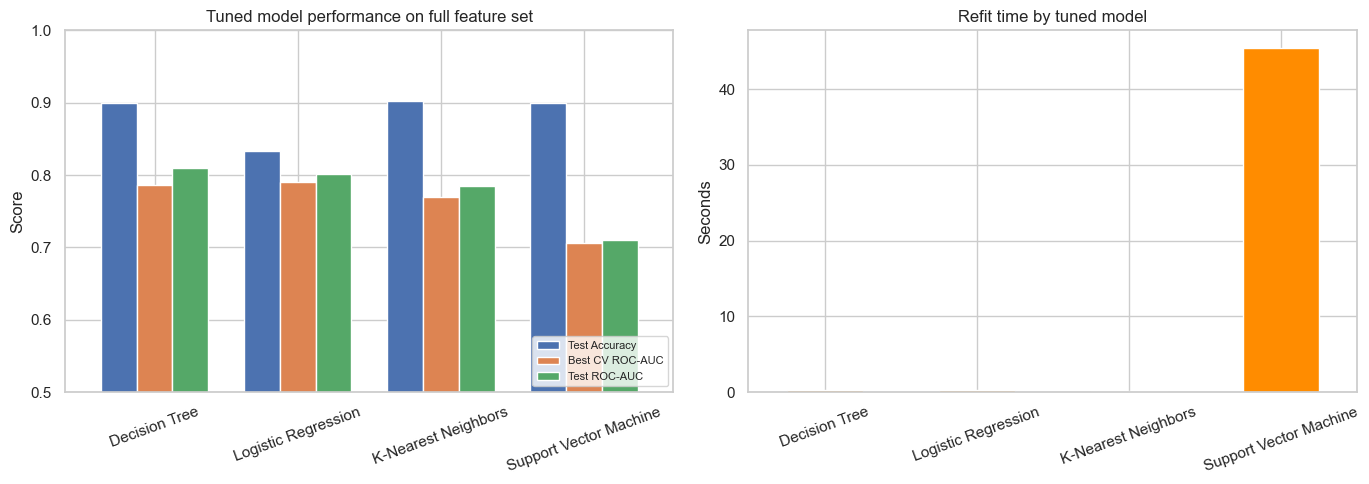

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

improved_results[["Test Accuracy", "Best CV ROC-AUC", "Test ROC-AUC"]].plot(
    kind="bar", ax=axes[0], width=0.75
)
axes[0].set_title("Tuned model performance on full feature set")
axes[0].set_xlabel("")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0.5, 1.0)
axes[0].tick_params(axis="x", rotation=20)
axes[0].legend(loc="lower right", fontsize=8)

improved_results["Refit Time (s)"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Refit time by tuned model")
axes[1].set_xlabel("")
axes[1].set_ylabel("Seconds")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### ROC Curves and Confusion Matrix for the Tuned Models

ROC curves show the trade-off between the true-positive rate and false-positive rate across all thresholds. The best model by test ROC-AUC is highlighted below with a confusion matrix at the default 0.5 threshold.

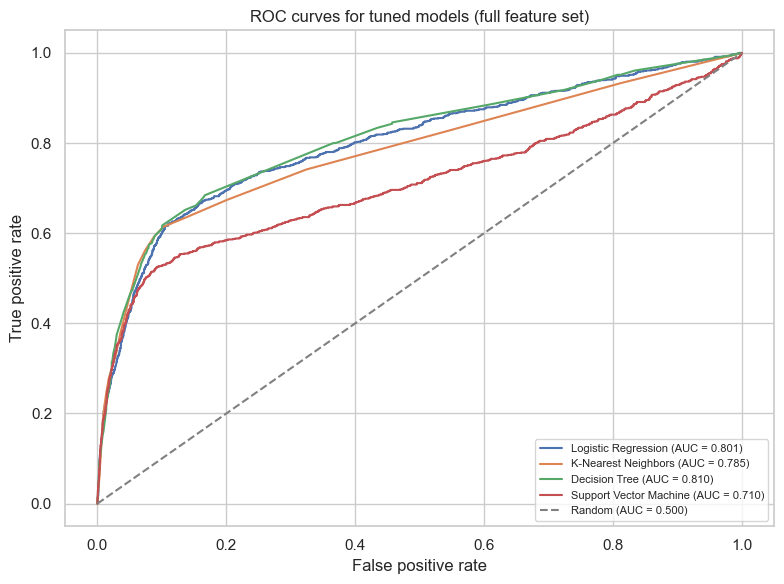

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, model in best_models.items():
    scores = get_scores(model, Xa_test)
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random (AUC = 0.500)")
ax.set_title("ROC curves for tuned models (full feature set)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

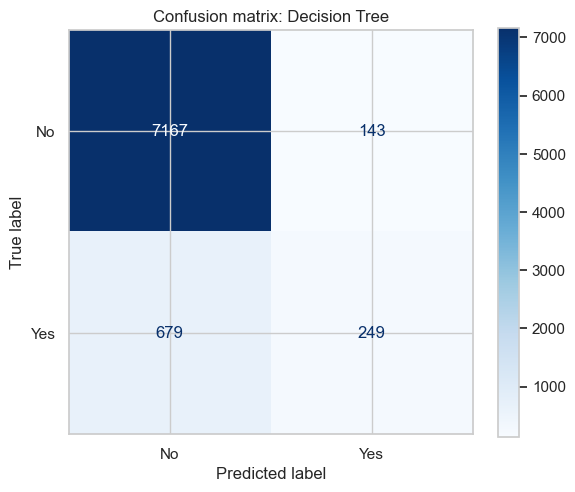

Best tuned model by test ROC-AUC: Decision Tree
              precision    recall  f1-score   support

          No      0.913     0.980     0.946      7310
         Yes      0.635     0.268     0.377       928

    accuracy                          0.900      8238
   macro avg      0.774     0.624     0.662      8238
weighted avg      0.882     0.900     0.882      8238



In [29]:
best_model_name = improved_results.index[0]
best_model = best_models[best_model_name]
best_pred = best_model.predict(Xa_test)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    display_labels=["No", "Yes"],
    cmap="Blues",
    ax=ax,
)
ax.set_title(f"Confusion matrix: {best_model_name}")
plt.tight_layout()
plt.show()

print(f"Best tuned model by test ROC-AUC: {best_model_name}")
print(classification_report(y_test, best_pred, target_names=["No", "Yes"], digits=3))

### Interpreting the Logistic Regression Coefficients

The tuned Logistic Regression is the most interpretable of the four models. Coefficients are on the log-odds scale: a positive coefficient increases the log-odds of subscribing, and a negative coefficient decreases it. Because the numeric features are standardized and categorical features are one-hot encoded, the magnitudes are comparable across features.

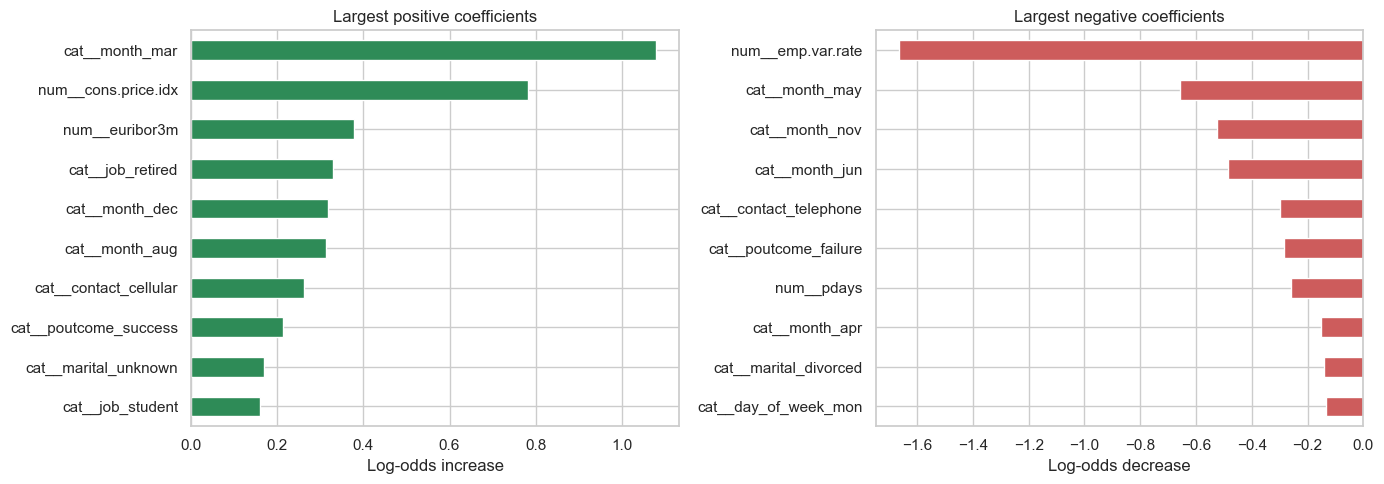

In [30]:
# Extract one coefficient per encoded feature from the tuned logistic model
best_log_model = best_models["Logistic Regression"]
log_preprocessor = best_log_model.named_steps["prep"]
log_classifier = best_log_model.named_steps["model"]

feature_names = log_preprocessor.get_feature_names_out()
coefficients = pd.Series(log_classifier.coef_[0], index=feature_names)

top_positive = coefficients.sort_values(ascending=False).head(10)
top_negative = coefficients.sort_values().head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top_positive.sort_values().plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Largest positive coefficients")
axes[0].set_xlabel("Log-odds increase")

top_negative.sort_values(ascending=False).plot(kind="barh", ax=axes[1], color="indianred")
axes[1].set_title("Largest negative coefficients")
axes[1].set_xlabel("Log-odds decrease")

plt.tight_layout()
plt.show()

Coefficient interpretation: The strongest positive coefficients identify features associated with a higher probability of subscribing, while the strongest negative coefficients identify features associated with a lower probability. Because one-hot encoding creates one coefficient per category, the signs should be read relative to the omitted reference category for each variable. These coefficients are associations and not causal effects.

## Findings

1. The business problem is imbalanced: Only about 11.3% of contacts result in a subscription, so a "predict no for everyone" rule already achieves roughly 88.7% accuracy while finding zero subscribers. Accuracy alone is therefore misleading.
2. Bank-only features have limited predictive power: The basic Logistic Regression, KNN, Decision Tree, and SVM models all cluster near the majority-class baseline on accuracy. The Decision Tree overfits, and KNN or SVM do not really outperform the simpler logistic benchmark. The best bank only model reaches only 0.649 ROC-AUC.
3. The tuned models trade off precision and recall: The tuned Decision Tree has the best test ROC-AUC but recalls only 26.8% of subscribers at the default threshold; the tuned Logistic Regression recalls 64.8% but with lower precision. The bank can adjust the threshold depending on call-center capacity and the relative cost of a wasted call versus a missed sale.
4. Job type and contact timing have larger influence: Students and retired clients have relatively high subscription rates, and certain months show much higher conversion. The job type and subscription are statistically associated (p-value effectively zero). 

## Recommendations

- Use the model as a prioritization tool, rather than as a blind decision maker: Rank clients by predicted probability and call the highest ranked clients first. Have a human review or a test and learn approach for borderline cases.
- Prefer the interpretable model unless the tree's precision advantage is decisive: Logistic Regression captures substantially more subscribers and is easier to explain to marketing stakeholders; the Decision Tree offers higher precision and a rule-based structure.
- Collect better features: The largest performance gains might probabaly come from additional client, product-usage, and campaign-history data rather than from a more complex classifier.
- Monitor drift and retrain: Economic indicators and campaign conditions can change over time. So better keep track of ROC-AUC, recall, precision, and conversion lift after deployment.